In [1]:
import sys
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np

# Add parent directory to path
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../helpers'))

# Import our modules
from helpers.scenario_loader import create_instance_from_csv
from helpers.online_wrapper import run_online_scheduling
from initial import run_scheduling, evaluate, construct_schedule

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

## 1. Load Scenarios

In [2]:
# Load both scenarios
normal_inst = create_instance_from_csv(scenario="normal")
earthquake_inst = create_instance_from_csv(scenario="earthquake", failure_scenario="earthquake_moderate")

print("=" * 60)
print("NORMAL DAY SCENARIO")
print("=" * 60)
print(f"Jobs: {len(normal_inst.jobs)}")
print(f"Machines: {len([s for s in normal_inst.servers.values() if not s.is_cloud])} local + {len([s for s in normal_inst.servers.values() if s.is_cloud])} cloud")
print(f"Time Horizon: {normal_inst.time_horizon} hours")
print(f"Machine Failures: {len(normal_inst.machine_failures) if normal_inst.machine_failures else 0}")

print("\n" + "=" * 60)
print("EARTHQUAKE EMERGENCY SCENARIO")
print("=" * 60)
print(f"Jobs: {len(earthquake_inst.jobs)}")
print(f"Machines: {len([s for s in earthquake_inst.servers.values() if not s.is_cloud])} local + {len([s for s in earthquake_inst.servers.values() if s.is_cloud])} cloud")
print(f"Time Horizon: {earthquake_inst.time_horizon} hours")
print(f"Machine Failures: {len(earthquake_inst.machine_failures) if earthquake_inst.machine_failures else 0}")

# Show job priorities
normal_priorities = pd.Series([j.priority for j in normal_inst.jobs.values()]).value_counts()
earthquake_priorities = pd.Series([j.priority for j in earthquake_inst.jobs.values()]).value_counts()

print("\n" + "=" * 60)
print("JOB PRIORITIES")
print("=" * 60)
print("\nNormal Day:")
print(normal_priorities)
print("\nEarthquake Emergency:")
print(earthquake_priorities)

NORMAL DAY SCENARIO
Jobs: 16
Machines: 5 local + 5 cloud
Time Horizon: 24 hours
Machine Failures: 0

EARTHQUAKE EMERGENCY SCENARIO
Jobs: 25
Machines: 5 local + 5 cloud
Time Horizon: 24 hours
Machine Failures: 2

JOB PRIORITIES

Normal Day:
MEDIUM      6
LOW         5
HIGH        3
CRITICAL    2
Name: count, dtype: int64

Earthquake Emergency:
MEDIUM      7
CRITICAL    7
HIGH        6
LOW         5
Name: count, dtype: int64


In [3]:
# Test with random failures enabled
normal_inst_random = create_instance_from_csv(
    scenario="normal",
    enable_random_failures=True,
    random_failure_rate=12.0,  # Mean hours between failures per machine
    random_seed=42  # For reproducibility
)

earthquake_inst_random = create_instance_from_csv(
    scenario="earthquake",
    failure_scenario="earthquake_moderate",
    enable_random_failures=True,
    random_failure_rate=8.0,  # More frequent under stress
    random_seed=42
)

print("=" * 60)
print("WITH RANDOM BACKGROUND FAILURES")
print("=" * 60)
print(f"\nNormal Scenario:")
print(f"  Total Failures: {len(normal_inst_random.machine_failures) if normal_inst_random.machine_failures else 0}")
random_normal = [f for f in normal_inst_random.machine_failures if f.is_random] if normal_inst_random.machine_failures else []
print(f"  - Random: {len(random_normal)}")

print(f"\nEarthquake Scenario:")
print(f"  Total Failures: {len(earthquake_inst_random.machine_failures) if earthquake_inst_random.machine_failures else 0}")
major_eq = [f for f in earthquake_inst_random.machine_failures if not f.is_random] if earthquake_inst_random.machine_failures else []
random_eq = [f for f in earthquake_inst_random.machine_failures if f.is_random] if earthquake_inst_random.machine_failures else []
print(f"  - Major (earthquake): {len(major_eq)}")
print(f"  - Random: {len(random_eq)}")

# Show sample random failures
if random_normal:
    print(f"\nSample Random Failures (Normal):")
    for i, f in enumerate(random_normal[:5]):
        print(f"  {i+1}. {f.machine_id}: t={f.failure_start}-{f.failure_end}, capacity -{f.capacity_reduction}")

WITH RANDOM BACKGROUND FAILURES

Normal Scenario:
  Total Failures: 7
  - Random: 7

Earthquake Scenario:
  Total Failures: 22
  - Major (earthquake): 2
  - Random: 20

Sample Random Failures (Normal):
  1. M1: t=5-6, capacity -3
  2. M2: t=15-16, capacity -1
  3. M3: t=2-4, capacity -1
  4. M3: t=4-5, capacity -1
  5. M3: t=4-5, capacity -1


### 1.1 Add Random Background Failures (Optional)

You can enable random background failures to simulate realistic operational issues:

## 2. Run Multi-Scenario Evaluation

In [ ]:
# Run clairvoyant scheduler for both scenarios (sees all jobs upfront)
print("=" * 60)
print("CLAIRVOYANT SCHEDULER (Perfect Future Knowledge)")
print("=" * 60)

clairvoyant_normal_sched = construct_schedule(normal_inst)
clairvoyant_normal_fit = evaluate(normal_inst, clairvoyant_normal_sched)
clairvoyant_normal_score = float(clairvoyant_normal_fit.score)

clairvoyant_eq_sched = construct_schedule(earthquake_inst)
clairvoyant_eq_fit = evaluate(earthquake_inst, clairvoyant_eq_sched)
clairvoyant_eq_score = float(clairvoyant_eq_fit.score)

print(f"\nNormal Scenario:")
print(f"  Cost: ¥{clairvoyant_normal_score:.2f}")
print(f"    - Compute: ¥{clairvoyant_normal_fit.compute_cost:.2f}")
print(f"    - Delays: ¥{clairvoyant_normal_fit.delay_penalty:.2f}")
print(f"  Valid: {clairvoyant_normal_fit.is_valid()}")
print(f"  Violations: {len(clairvoyant_normal_fit.violations)}")

print(f"\nEarthquake Scenario:")
print(f"  Cost: ¥{clairvoyant_eq_score:.2f}")
print(f"    - Compute: ¥{clairvoyant_eq_fit.compute_cost:.2f}")
print(f"    - Delays: ¥{clairvoyant_eq_fit.delay_penalty:.2f}")
print(f"  Valid: {clairvoyant_eq_fit.is_valid()}")
print(f"  Violations: {len(clairvoyant_eq_fit.violations)}")

clairvoyant_weighted = 0.8 * clairvoyant_normal_score + 0.2 * clairvoyant_eq_score
print(f"\nWeighted Score: ¥{clairvoyant_weighted:.2f}")
print(f"  (0.8 × {clairvoyant_normal_score:.2f} + 0.2 × {clairvoyant_eq_score:.2f})")

TypeError: run_scheduling() got an unexpected keyword argument 'multi_scenario'

In [ ]:
# Run clairvoyant scheduler with random failures
print("=" * 60)
print("CLAIRVOYANT SCHEDULER WITH RANDOM FAILURES")
print("=" * 60)

clairvoyant_normal_rf_sched = construct_schedule(normal_inst_random)
clairvoyant_normal_rf_fit = evaluate(normal_inst_random, clairvoyant_normal_rf_sched)
clairvoyant_normal_rf_score = float(clairvoyant_normal_rf_fit.score)

clairvoyant_eq_rf_sched = construct_schedule(earthquake_inst_random)
clairvoyant_eq_rf_fit = evaluate(earthquake_inst_random, clairvoyant_eq_rf_sched)
clairvoyant_eq_rf_score = float(clairvoyant_eq_rf_fit.score)

print(f"\nNormal Scenario:")
print(f"  Cost: ¥{clairvoyant_normal_rf_score:.2f}")
print(f"    - Compute: ¥{clairvoyant_normal_rf_fit.compute_cost:.2f}")
print(f"    - Delays: ¥{clairvoyant_normal_rf_fit.delay_penalty:.2f}")
print(f"  Valid: {clairvoyant_normal_rf_fit.is_valid()}")
print(f"  Violations: {len(clairvoyant_normal_rf_fit.violations)}")

print(f"\nEarthquake Scenario:")
print(f"  Cost: ¥{clairvoyant_eq_rf_score:.2f}")
print(f"    - Compute: ¥{clairvoyant_eq_rf_fit.compute_cost:.2f}")
print(f"    - Delays: ¥{clairvoyant_eq_rf_fit.delay_penalty:.2f}")
print(f"  Valid: {clairvoyant_eq_rf_fit.is_valid()}")
print(f"  Violations: {len(clairvoyant_eq_rf_fit.violations)}")

clairvoyant_weighted_rf = 0.8 * clairvoyant_normal_rf_score + 0.2 * clairvoyant_eq_rf_score
print(f"\nWeighted Score: ¥{clairvoyant_weighted_rf:.2f}")
print(f"  (0.8 × {clairvoyant_normal_rf_score:.2f} + 0.2 × {clairvoyant_eq_rf_score:.2f})")

# Impact analysis
print("\n" + "=" * 60)
print("RANDOM FAILURE IMPACT ON CLAIRVOYANT")
print("=" * 60)
normal_impact = ((clairvoyant_normal_rf_score - clairvoyant_normal_score) / clairvoyant_normal_score * 100) if clairvoyant_normal_score > 0 else 0
eq_impact = ((clairvoyant_eq_rf_score - clairvoyant_eq_score) / clairvoyant_eq_score * 100) if clairvoyant_eq_score > 0 else 0
weighted_impact = ((clairvoyant_weighted_rf - clairvoyant_weighted) / clairvoyant_weighted * 100) if clairvoyant_weighted > 0 else 0

print(f"\nCost Impact from Random Failures:")
print(f"  Normal: +{normal_impact:.2f}% (+¥{clairvoyant_normal_rf_score - clairvoyant_normal_score:.2f})")
print(f"  Earthquake: +{eq_impact:.2f}% (+¥{clairvoyant_eq_rf_score - clairvoyant_eq_score:.2f})")
print(f"  Weighted: +{weighted_impact:.2f}% (+¥{clairvoyant_weighted_rf - clairvoyant_weighted:.2f})")

FIFO SCHEDULER WITH RANDOM FAILURES

Normal Scenario:
  Cost: ¥4360.00
    - Compute: ¥4360.00
    - Delays: ¥0.00
  Valid: True
  Violations: 0

Earthquake Scenario:
  Cost: ¥12765.00
    - Compute: ¥9700.00
    - Delays: ¥613.00
  Valid: True
  Violations: 0

Weighted Score: ¥6041.00
  (0.8 × 4360.00 + 0.2 × 12765.00)

RANDOM FAILURE IMPACT

Cost Impact from Random Failures:
  Normal: +0.00% (+¥0.00)
  Earthquake: +0.00% (+¥0.00)
  Weighted: +0.00% (+¥0.00)


### 2.1 Compare with Random Failures

## 3. Online vs Clairvoyant Comparison

This section compares two fundamentally different scheduling approaches:
- **Online**: Realistic - only sees jobs as they arrive (no future knowledge)
- **Clairvoyant**: Theoretical benchmark - sees all future arrivals upfront

In [ ]:
# Run online scheduler (no future knowledge)
print("="*70)
print("ONLINE SCHEDULER (No Future Knowledge)")
print("="*70)
print("Jobs revealed incrementally as they arrive")
print("Cannot see or plan for future jobs\n")

online_normal_sched, online_normal_fit, online_normal_score = run_online_scheduling("normal")
online_eq_sched, online_eq_fit, online_eq_score = run_online_scheduling("earthquake", "earthquake_moderate")

print(f"Normal Scenario:")
print(f"  Cost: ¥{online_normal_score:.2f} (Valid: {online_normal_fit.is_valid()})")
print(f"    - Compute: ¥{online_normal_fit.compute_cost:.2f}")
print(f"    - Delay: ¥{online_normal_fit.delay_penalty:.2f}")

print(f"\nEarthquake Scenario:")
print(f"  Cost: ¥{online_eq_score:.2f} (Valid: {online_eq_fit.is_valid()})")
print(f"    - Compute: ¥{online_eq_fit.compute_cost:.2f}")
print(f"    - Delay: ¥{online_eq_fit.delay_penalty:.2f}")

online_weighted = 0.8 * online_normal_score + 0.2 * online_eq_score
print(f"\nWeighted (80% normal + 20% earthquake): ¥{online_weighted:.2f}")

# Run clairvoyant (perfect future knowledge)
print("\n" + "="*70)
print("CLAIRVOYANT SCHEDULER (Perfect Future Knowledge)")
print("="*70)
print("Sees all jobs and arrivals upfront")
print("Can globally optimize priorities\n")

clairvoyant_normal_inst = create_instance_from_csv("normal")
clairvoyant_normal_sched = construct_schedule(clairvoyant_normal_inst)
clairvoyant_normal_fit = evaluate(clairvoyant_normal_inst, clairvoyant_normal_sched)

clairvoyant_eq_inst = create_instance_from_csv("earthquake", "earthquake_moderate")
clairvoyant_eq_sched = construct_schedule(clairvoyant_eq_inst)
clairvoyant_eq_fit = evaluate(clairvoyant_eq_inst, clairvoyant_eq_sched)

clairvoyant_normal_score = float(clairvoyant_normal_fit.score)
clairvoyant_eq_score = float(clairvoyant_eq_fit.score)

print(f"Normal Scenario:")
print(f"  Cost: ¥{clairvoyant_normal_score:.2f} (Valid: {clairvoyant_normal_fit.is_valid()})")
print(f"    - Compute: ¥{clairvoyant_normal_fit.compute_cost:.2f}")
print(f"    - Delay: ¥{clairvoyant_normal_fit.delay_penalty:.2f}")

print(f"\nEarthquake Scenario:")
print(f"  Cost: ¥{clairvoyant_eq_score:.2f} (Valid: {clairvoyant_eq_fit.is_valid()})")
print(f"    - Compute: ¥{clairvoyant_eq_fit.compute_cost:.2f}")
print(f"    - Delay: ¥{clairvoyant_eq_fit.delay_penalty:.2f}")

clairvoyant_weighted = 0.8 * clairvoyant_normal_score + 0.2 * clairvoyant_eq_score
print(f"\nWeighted (80% normal + 20% earthquake): ¥{clairvoyant_weighted:.2f}")

# Calculate competitive ratio
print("\n" + "="*70)
print("COMPETITIVE RATIO (Online vs Clairvoyant)")
print("="*70)

normal_ratio = online_normal_score / clairvoyant_normal_score if clairvoyant_normal_score > 0 else 1.0
eq_ratio = online_eq_score / clairvoyant_eq_score if clairvoyant_eq_score > 0 else 1.0
weighted_ratio = online_weighted / clairvoyant_weighted if clairvoyant_weighted > 0 else 1.0

print(f"\nNormal: {normal_ratio:.3f}x")
print(f"  Gap: ¥{online_normal_score - clairvoyant_normal_score:.2f} ({(normal_ratio-1)*100:.1f}% worse)")

print(f"\nEarthquake: {eq_ratio:.3f}x")
print(f"  Gap: ¥{online_eq_score - clairvoyant_eq_score:.2f} ({(eq_ratio-1)*100:.1f}% worse)")

print(f"\nWeighted: {weighted_ratio:.3f}x")
print(f"  Gap: ¥{online_weighted - clairvoyant_weighted:.2f} ({(weighted_ratio-1)*100:.1f}% worse)")

print("\n💡 The online algorithm pays {:.1f}x what clairvoyant pays on average".format(weighted_ratio))

### 3.1 Visualize Online vs Clairvoyant Schedules

In [ ]:
def visualize_comparison(inst, online_schedule, clairvoyant_schedule, title="Online vs Clairvoyant"):
    """Compare online and clairvoyant schedules side-by-side."""
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10))
    
    # Get all jobs for consistent coloring
    all_jobs = sorted(inst.jobs.keys())
    job_cmap = plt.cm.get_cmap('tab20', len(all_jobs))
    job_colors = {job_id: job_cmap(i / len(all_jobs)) for i, job_id in enumerate(all_jobs)}
    
    # Get all machines (local only for cleaner visualization)
    local_machines = sorted([s.id for s in inst.servers.values() if not s.is_cloud])
    machine_indices = {m: i for i, m in enumerate(local_machines)}
    
    def plot_schedule(ax, schedule, subtitle):
        max_end_time = inst.time_horizon
        
        for job_id, ops in schedule.items():
            for op in ops:
                server = op['server']
                if server not in machine_indices:  # Skip cloud machines
                    continue
                    
                start = op['start']
                job = inst.jobs[job_id]
                duration = next((o.duration for o in job.operations if True), 1)
                end = start + duration
                max_end_time = max(max_end_time, end)
                
                y_pos = machine_indices[server]
                rect = mpatches.Rectangle(
                    (start, y_pos - 0.4), duration, 0.8,
                    facecolor=job_colors[job_id], 
                    edgecolor='black', 
                    linewidth=0.5,
                    alpha=0.8
                )
                ax.add_patch(rect)
                
                # Add job label
                ax.text(start + duration/2, y_pos, job_id,
                       ha='center', va='center', fontsize=7, weight='bold')
        
        # Styling
        ax.set_ylim(-0.5, len(local_machines) - 0.5)
        ax.set_xlim(0, max_end_time)
        ax.set_yticks(range(len(local_machines)))
        ax.set_yticklabels(local_machines)
        ax.set_xlabel('Time (hours)', fontsize=12)
        ax.set_ylabel('Machine', fontsize=12)
        ax.set_title(subtitle, fontsize=14, weight='bold')
        ax.grid(True, axis='x', alpha=0.3)
        
        # Add time horizon marker
        if max_end_time > inst.time_horizon:
            ax.axvline(inst.time_horizon, color='red', linestyle='--', linewidth=2, 
                      label=f'Time Horizon ({inst.time_horizon}h)')
            ax.legend(loc='upper right')
    
    plot_schedule(ax1, online_schedule, "Online (No Future Knowledge)")
    plot_schedule(ax2, clairvoyant_schedule, "Clairvoyant (Perfect Knowledge)")
    
    fig.suptitle(title, fontsize=16, weight='bold', y=0.995)
    plt.tight_layout()
    plt.show()

# Visualize normal scenario comparison
visualize_comparison(
    clairvoyant_normal_inst, 
    online_normal_sched, 
    clairvoyant_normal_sched,
    "Normal Scenario: Online vs Clairvoyant"
)

In [ ]:
# Visualize earthquake scenario comparison
visualize_comparison(
    clairvoyant_eq_inst, 
    online_eq_sched, 
    clairvoyant_eq_sched,
    "Earthquake Scenario: Online vs Clairvoyant"
)

## 4. Visualize Schedules

In [ ]:
def visualize_schedule(schedule, fitness, inst, title="Schedule Visualization"):
    """
    Visualize a schedule as a Gantt chart.
    """
    # Color map for priorities
    priority_colors = {
        'CRITICAL': '#d62728',  # Red
        'HIGH': '#ff7f0e',      # Orange
        'MEDIUM': '#2ca02c',    # Green
        'LOW': '#1f77b4'        # Blue
    }
    
    # Generate color map for jobs (unique color per job)
    import matplotlib.cm as cm
    all_jobs = sorted(schedule.keys())
    job_cmap = cm.get_cmap('tab20')
    job_colors = {job_id: job_cmap(i / len(all_jobs)) for i, job_id in enumerate(all_jobs)}
    
    # Prepare data
    gantt_data = []
    
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        for idx, op in enumerate(ops):
            server_id = op['server']
            start = op['start']
            duration = job.operations[idx].duration
            
            gantt_data.append({
                'job': job_id,
                'server': server_id,
                'server_type': inst.servers[server_id].server_type,
                'start': start,
                'duration': duration,
                'end': start + duration,
                'priority': job.priority,
                'is_cloud': inst.servers[server_id].is_cloud
            })
    
    df = pd.DataFrame(gantt_data)
    
    # Calculate actual time range needed (to show jobs that go beyond time_horizon)
    max_end_time = df['end'].max() if not df.empty else inst.time_horizon
    time_limit = max(inst.time_horizon, max_end_time)
    
    # Create figure
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), height_ratios=[3, 1])
    
    # === Top plot: Schedule by Machine (colored by Job) ===
    servers = sorted(df['server'].unique())
    server_to_y = {s: i for i, s in enumerate(servers)}
    
    for _, row in df.iterrows():
        y_pos = server_to_y[row['server']]
        color = job_colors[row['job']]
        alpha = 0.7 if row['is_cloud'] else 1.0
        
        ax1.barh(y_pos, row['duration'], left=row['start'], 
                height=0.8, color=color, alpha=alpha, 
                edgecolor='black', linewidth=0.5)
        
        # Add job label
        ax1.text(row['start'] + row['duration']/2, y_pos, row['job'],
                ha='center', va='center', fontsize=7, fontweight='bold')
    
    ax1.set_yticks(range(len(servers)))
    ax1.set_yticklabels(servers)
    ax1.set_xlabel('Time (hours)', fontsize=11)
    ax1.set_ylabel('Machine', fontsize=11)
    ax1.set_title(f'{title}\nMachine Utilization (colored by Job)', fontsize=12, fontweight='bold')
    ax1.grid(axis='x', alpha=0.3)
    ax1.set_xlim(0, time_limit)
    
    # Add vertical line at time_horizon if jobs extend beyond it
    if max_end_time > inst.time_horizon:
        ax1.axvline(x=inst.time_horizon, color='red', linestyle='--', linewidth=2, alpha=0.7, label=f'Time Horizon ({inst.time_horizon}h)')
        ax1.legend(loc='upper right', fontsize=9)
    
    # === Bottom plot: Timeline by Priority ===
    for _, row in df.iterrows():
        color = priority_colors.get(row['priority'], '#999999')
        ax2.barh(0, row['duration'], left=row['start'],
                height=0.8, color=color, alpha=0.7,
                edgecolor='black', linewidth=0.5)
    
    ax2.set_yticks([0])
    ax2.set_yticklabels(['Jobs'])
    ax2.set_xlabel('Time (hours)', fontsize=11)
    ax2.set_title('Job Priority Timeline', fontsize=12, fontweight='bold')
    ax2.grid(axis='x', alpha=0.3)
    ax2.set_xlim(0, time_limit)
    
    # Add vertical line at time_horizon if jobs extend beyond it
    if max_end_time > inst.time_horizon:
        ax2.axvline(x=inst.time_horizon, color='red', linestyle='--', linewidth=2, alpha=0.7)
    
    # Add legend for priorities (bottom plot)
    priority_patches = [mpatches.Patch(color=color, label=prio) 
                       for prio, color in priority_colors.items()]
    ax2.legend(handles=priority_patches, loc='upper right', fontsize=9)
    
    # Add cost info
    info_text = f"Cost: ¥{fitness.score:.2f}\nCompute: ¥{fitness.compute_cost:.2f}\nDelays: ¥{fitness.delay_penalty:.2f}\nValid: {fitness.is_valid()}"
    ax1.text(0.02, 0.98, info_text, transform=ax1.transAxes,
            fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    plt.tight_layout()
    plt.show()

### 4.1 Normal Day - Clairvoyant Schedule

/var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/ipykernel_52155/3407456650.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  job_cmap = cm.get_cmap('tab20')


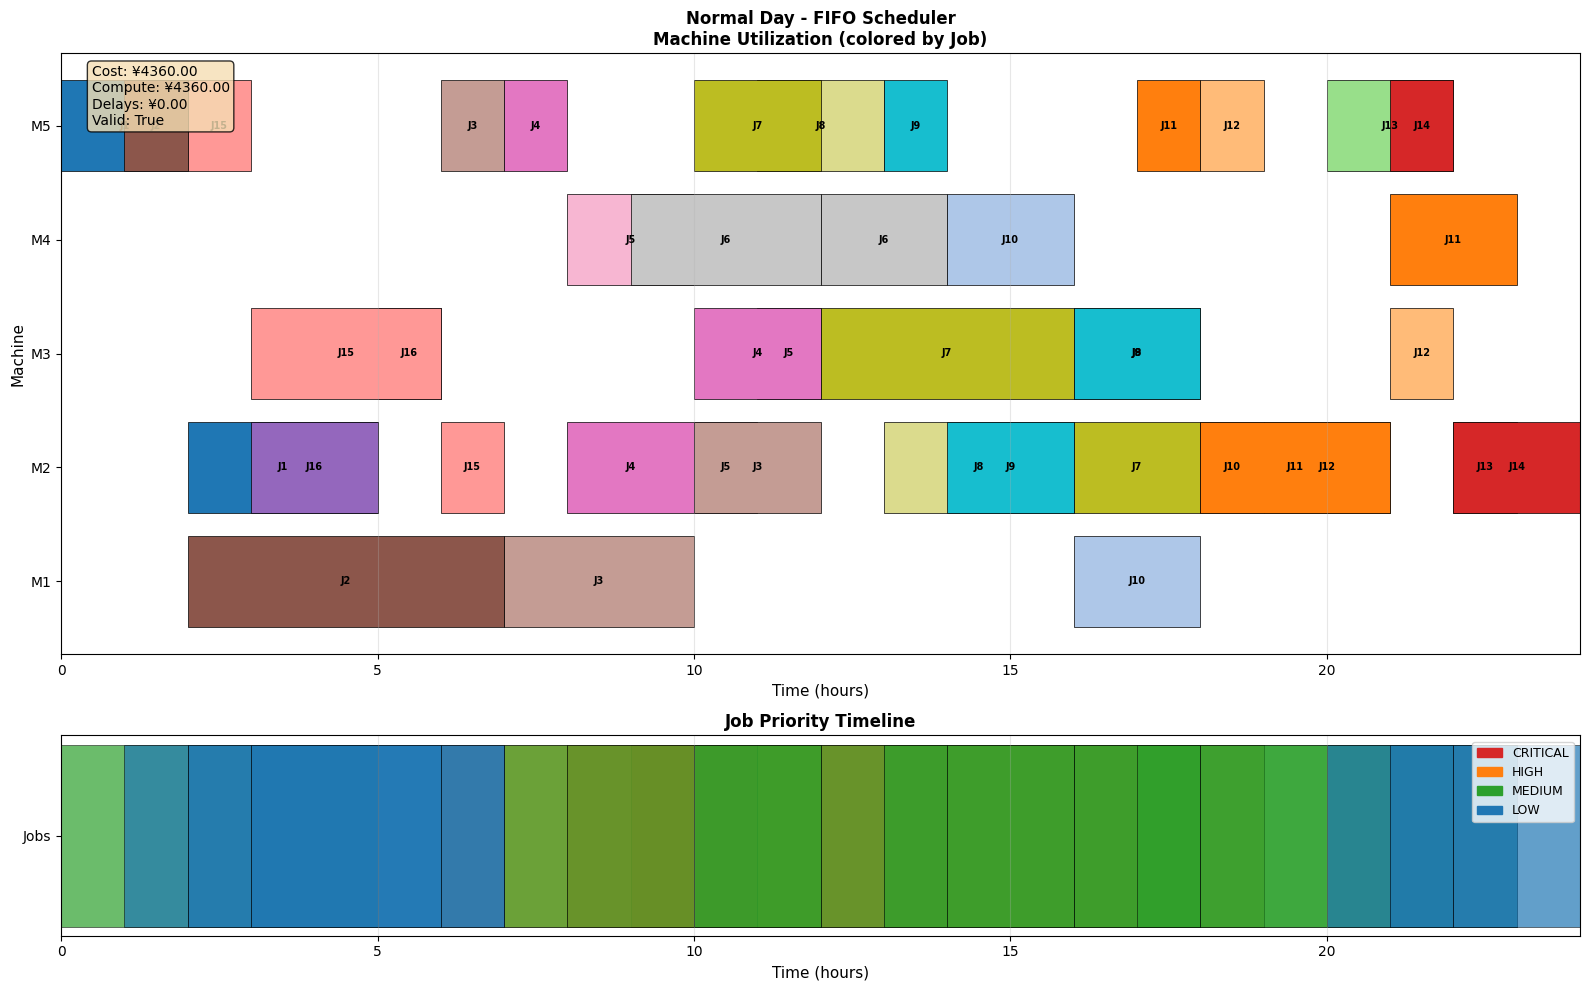

In [ ]:
visualize_schedule(clairvoyant_normal_sched, clairvoyant_normal_fit, normal_inst, 
                  "Normal Day - Clairvoyant Scheduler")

### 4.2 Normal Day - Online Schedule

/var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/ipykernel_52155/3407456650.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  job_cmap = cm.get_cmap('tab20')


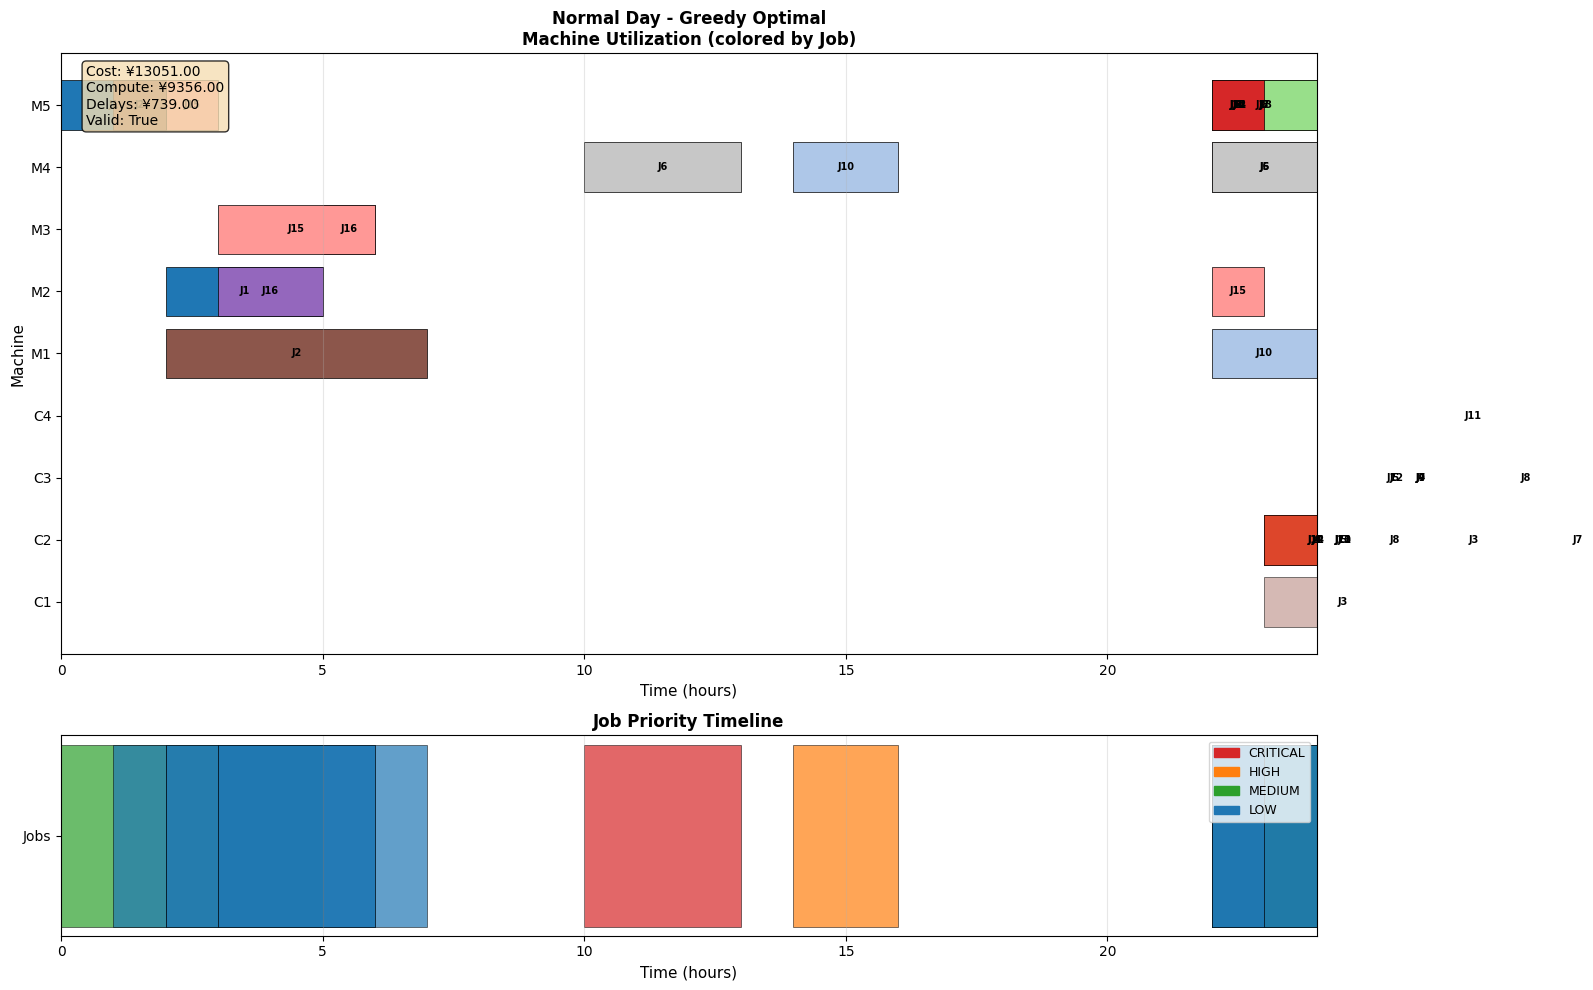

In [ ]:
visualize_schedule(online_normal_sched, online_normal_fit, normal_inst,
                  "Normal Day - Online Scheduler")

### 4.3 Earthquake - Clairvoyant Schedule

/var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/ipykernel_52155/3407456650.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  job_cmap = cm.get_cmap('tab20')


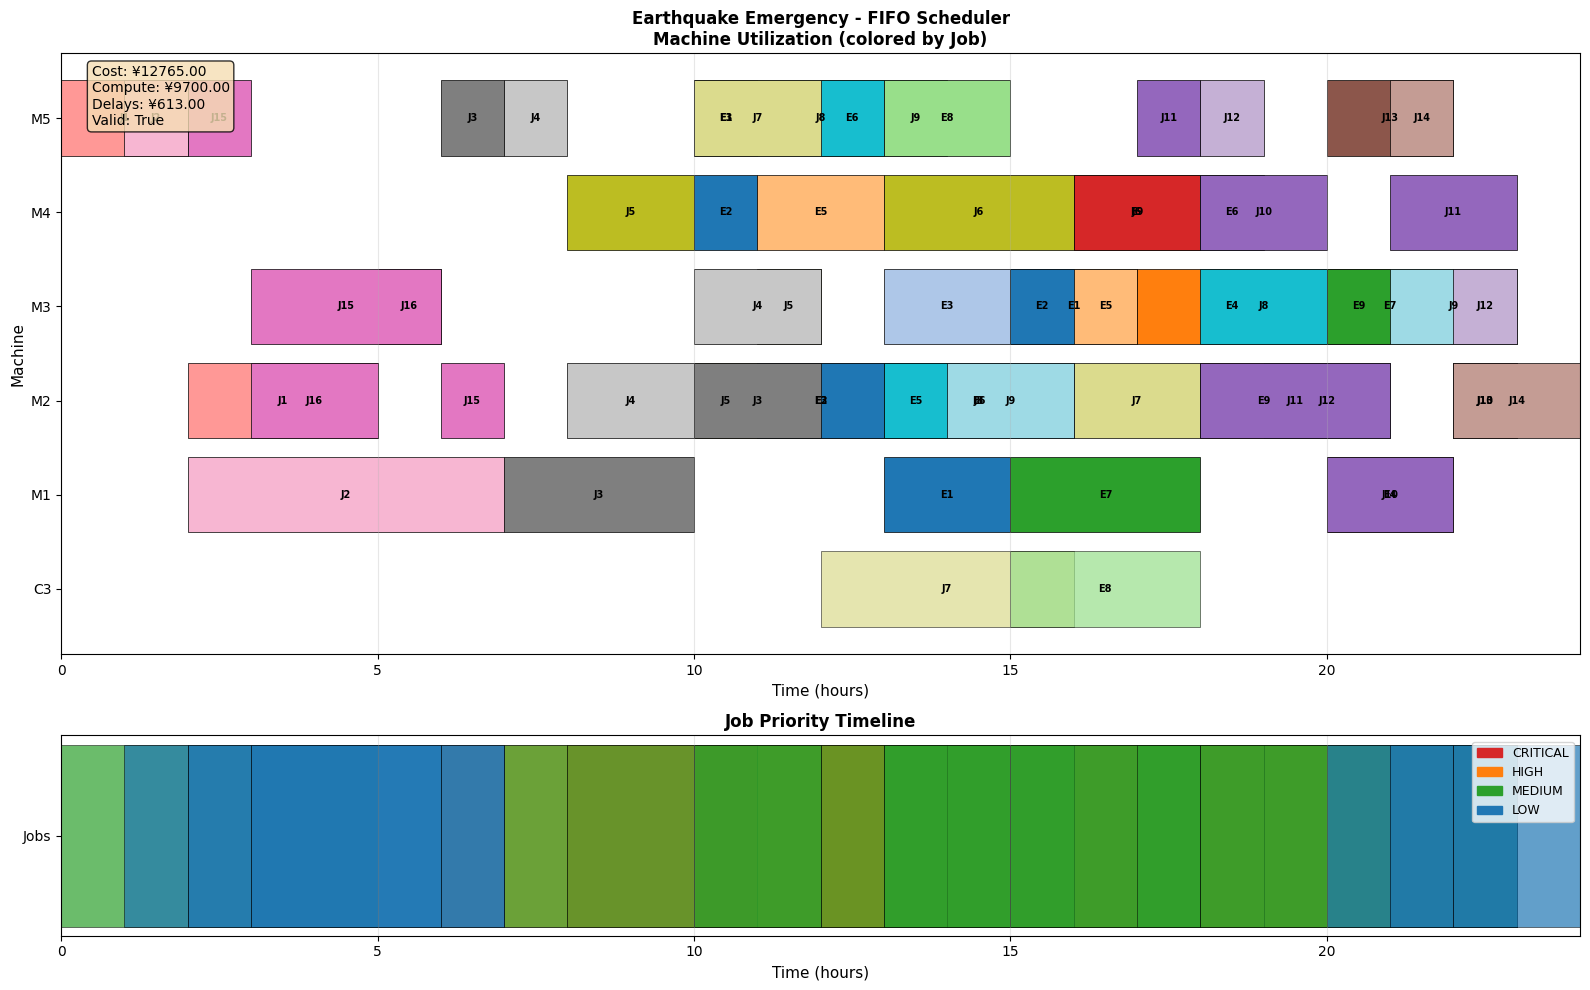

In [ ]:
visualize_schedule(clairvoyant_eq_sched, clairvoyant_eq_fit, earthquake_inst,
                  "Earthquake Emergency - Clairvoyant Scheduler")

### 4.4 Earthquake - Online Schedule

/var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/ipykernel_52155/3407456650.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  job_cmap = cm.get_cmap('tab20')


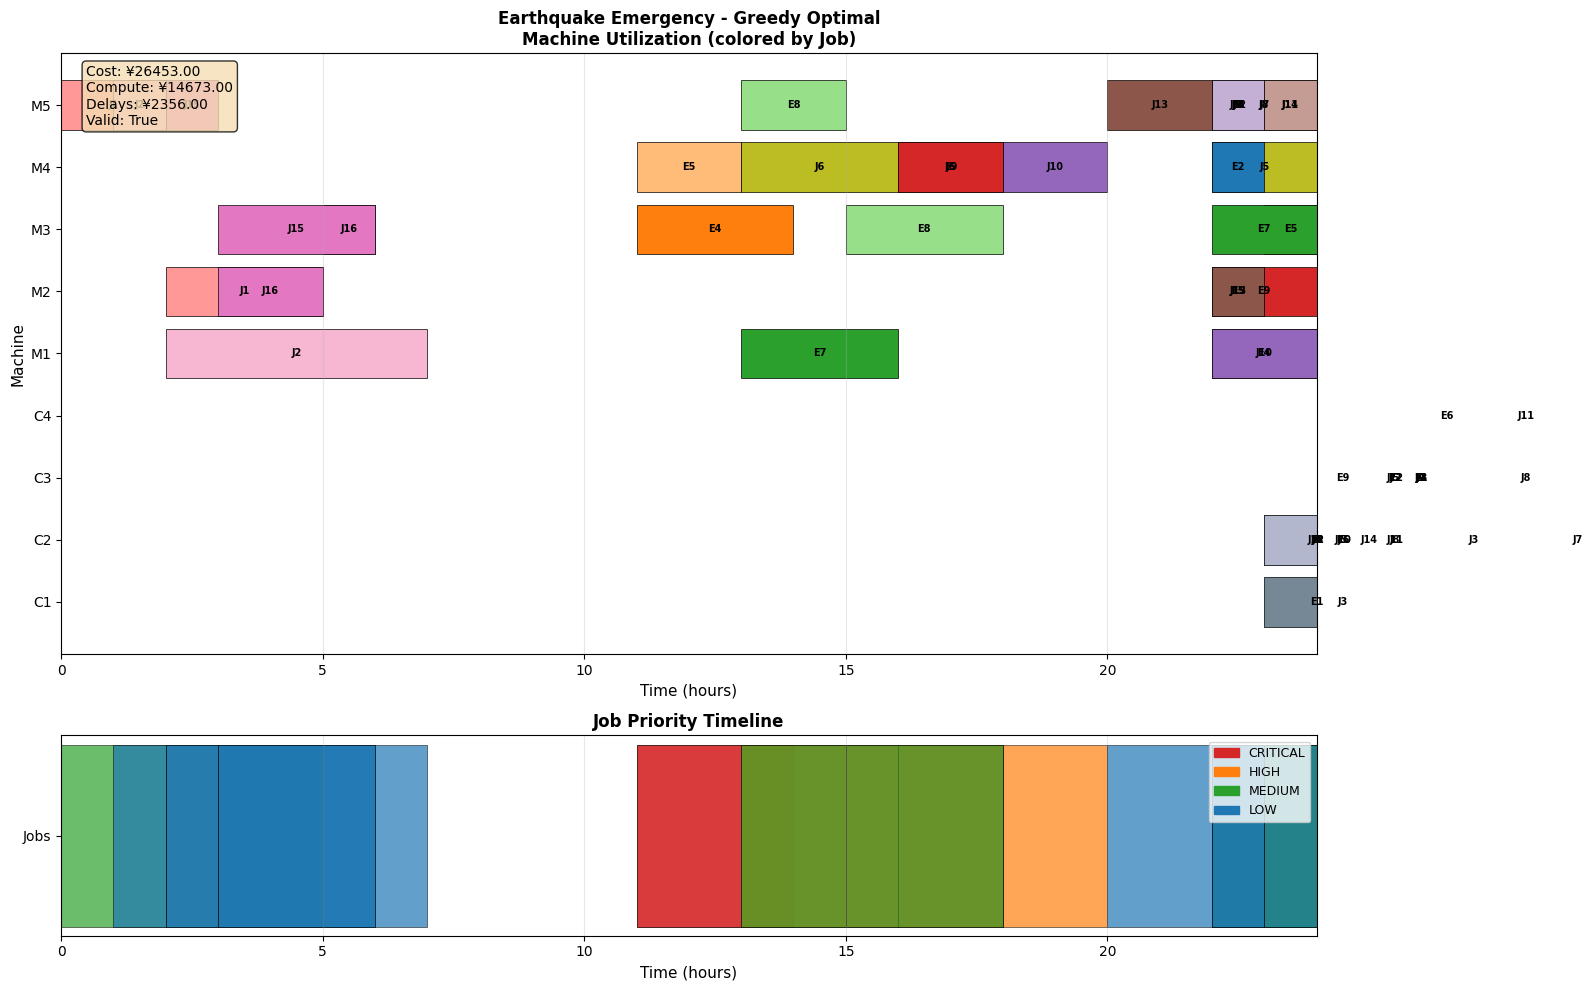

In [ ]:
visualize_schedule(online_eq_sched, online_eq_fit, earthquake_inst,
                  "Earthquake Emergency - Online Scheduler")

## 5. Machine Utilization Analysis

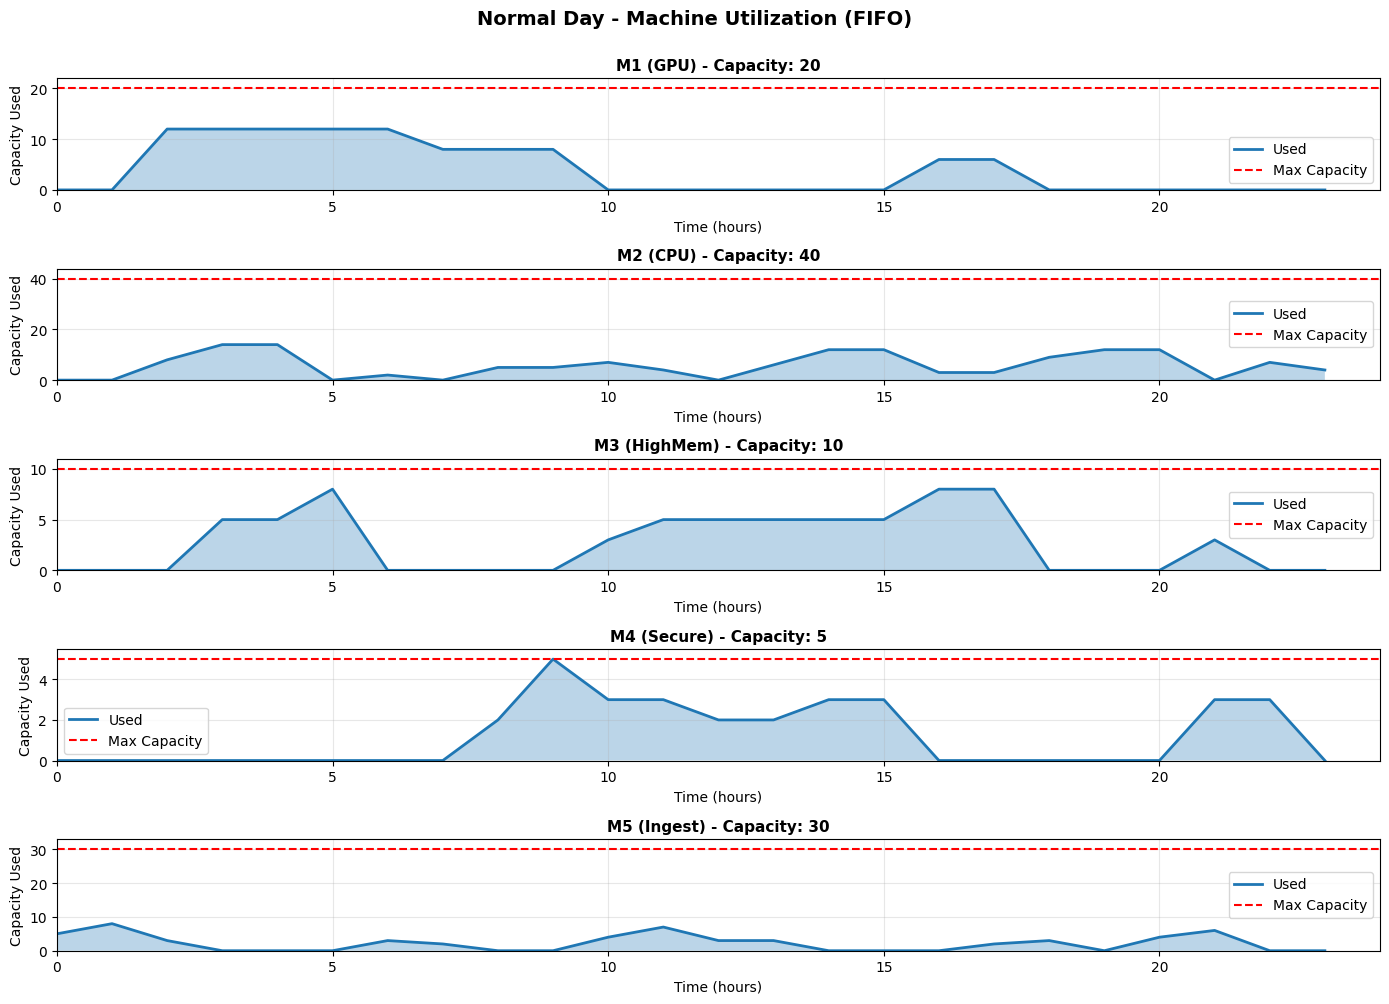

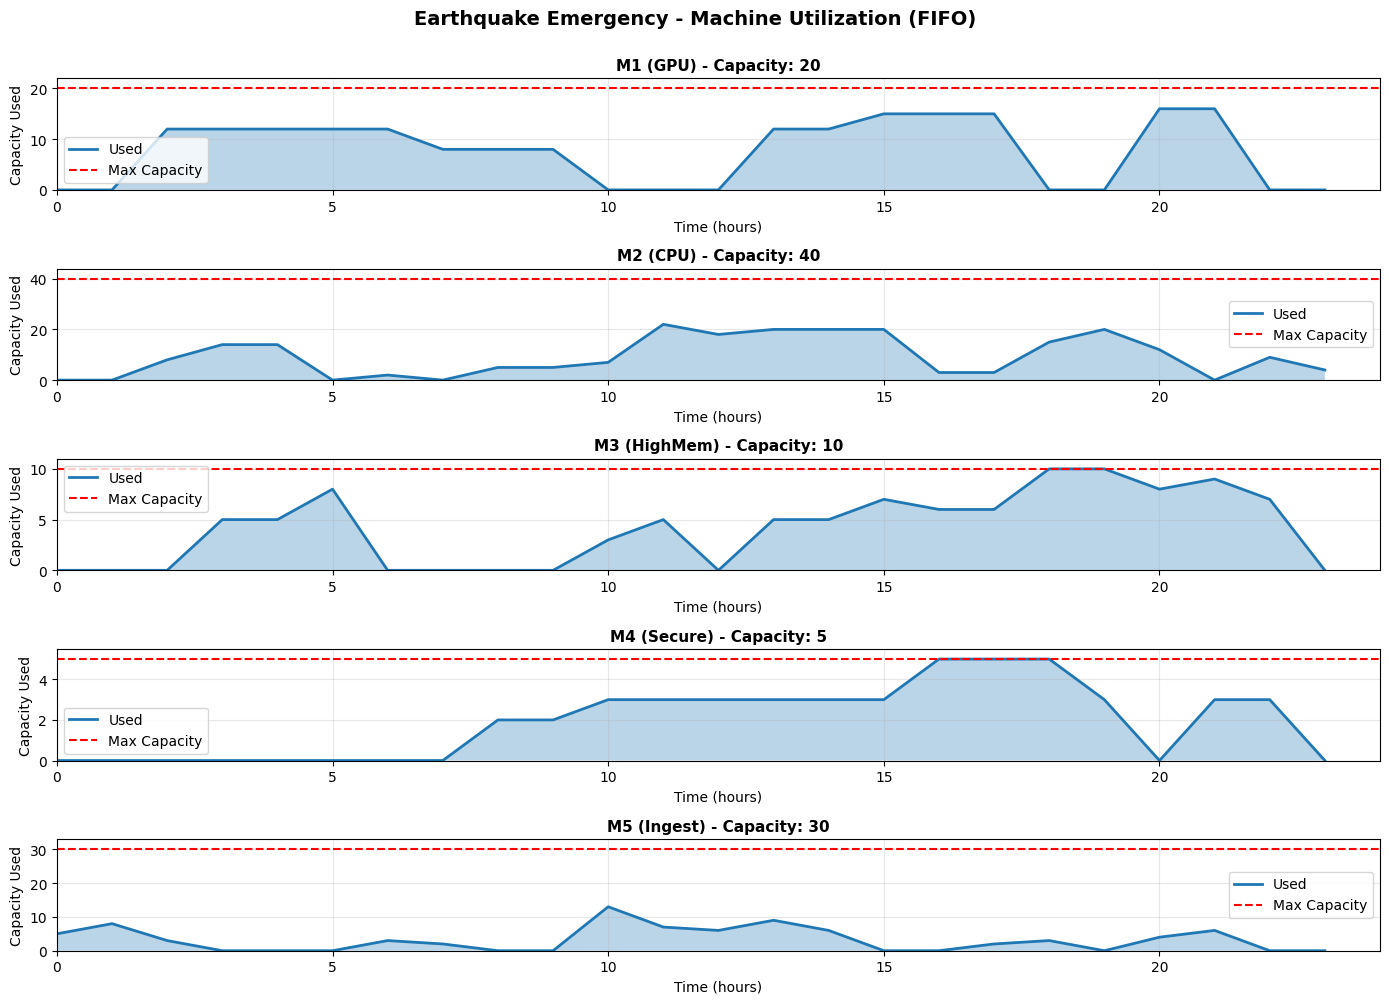

In [ ]:
def analyze_utilization(schedule, inst, title="Machine Utilization"):
    """
    Analyze machine utilization over time.
    """
    # Track capacity usage
    capacity_usage = {s: [0] * inst.time_horizon for s in inst.servers}
    
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        for idx, op in enumerate(ops):
            server_id = op['server']
            start = op['start']
            duration = job.operations[idx].duration
            capacity_req = job.operations[idx].capacity_required
            
            for t in range(start, min(start + duration, inst.time_horizon)):
                capacity_usage[server_id][t] += capacity_req
    
    # Plot utilization for local machines
    local_servers = [s for s in inst.servers if not inst.servers[s].is_cloud]
    
    fig, axes = plt.subplots(len(local_servers), 1, figsize=(14, len(local_servers)*2))
    if len(local_servers) == 1:
        axes = [axes]
    
    for idx, server_id in enumerate(sorted(local_servers)):
        server = inst.servers[server_id]
        usage = capacity_usage[server_id]
        
        axes[idx].plot(range(inst.time_horizon), usage, linewidth=2, label='Used')
        axes[idx].axhline(y=server.capacity, color='r', linestyle='--', label='Max Capacity')
        axes[idx].fill_between(range(inst.time_horizon), 0, usage, alpha=0.3)
        
        axes[idx].set_title(f'{server_id} ({server.server_type}) - Capacity: {server.capacity}',
                          fontsize=11, fontweight='bold')
        axes[idx].set_xlabel('Time (hours)')
        axes[idx].set_ylabel('Capacity Used')
        axes[idx].legend()
        axes[idx].grid(alpha=0.3)
        axes[idx].set_xlim(0, inst.time_horizon)
        axes[idx].set_ylim(0, max(max(usage), server.capacity) * 1.1)
    
    plt.suptitle(title, fontsize=14, fontweight='bold', y=1.0)
    plt.tight_layout()
    plt.show()

# Analyze both scenarios
analyze_utilization(clairvoyant_normal_sched, normal_inst, "Normal Day - Machine Utilization")
analyze_utilization(clairvoyant_eq_sched, earthquake_inst, "Earthquake Emergency - Machine Utilization")

## 6. Capacity Degradation Analysis

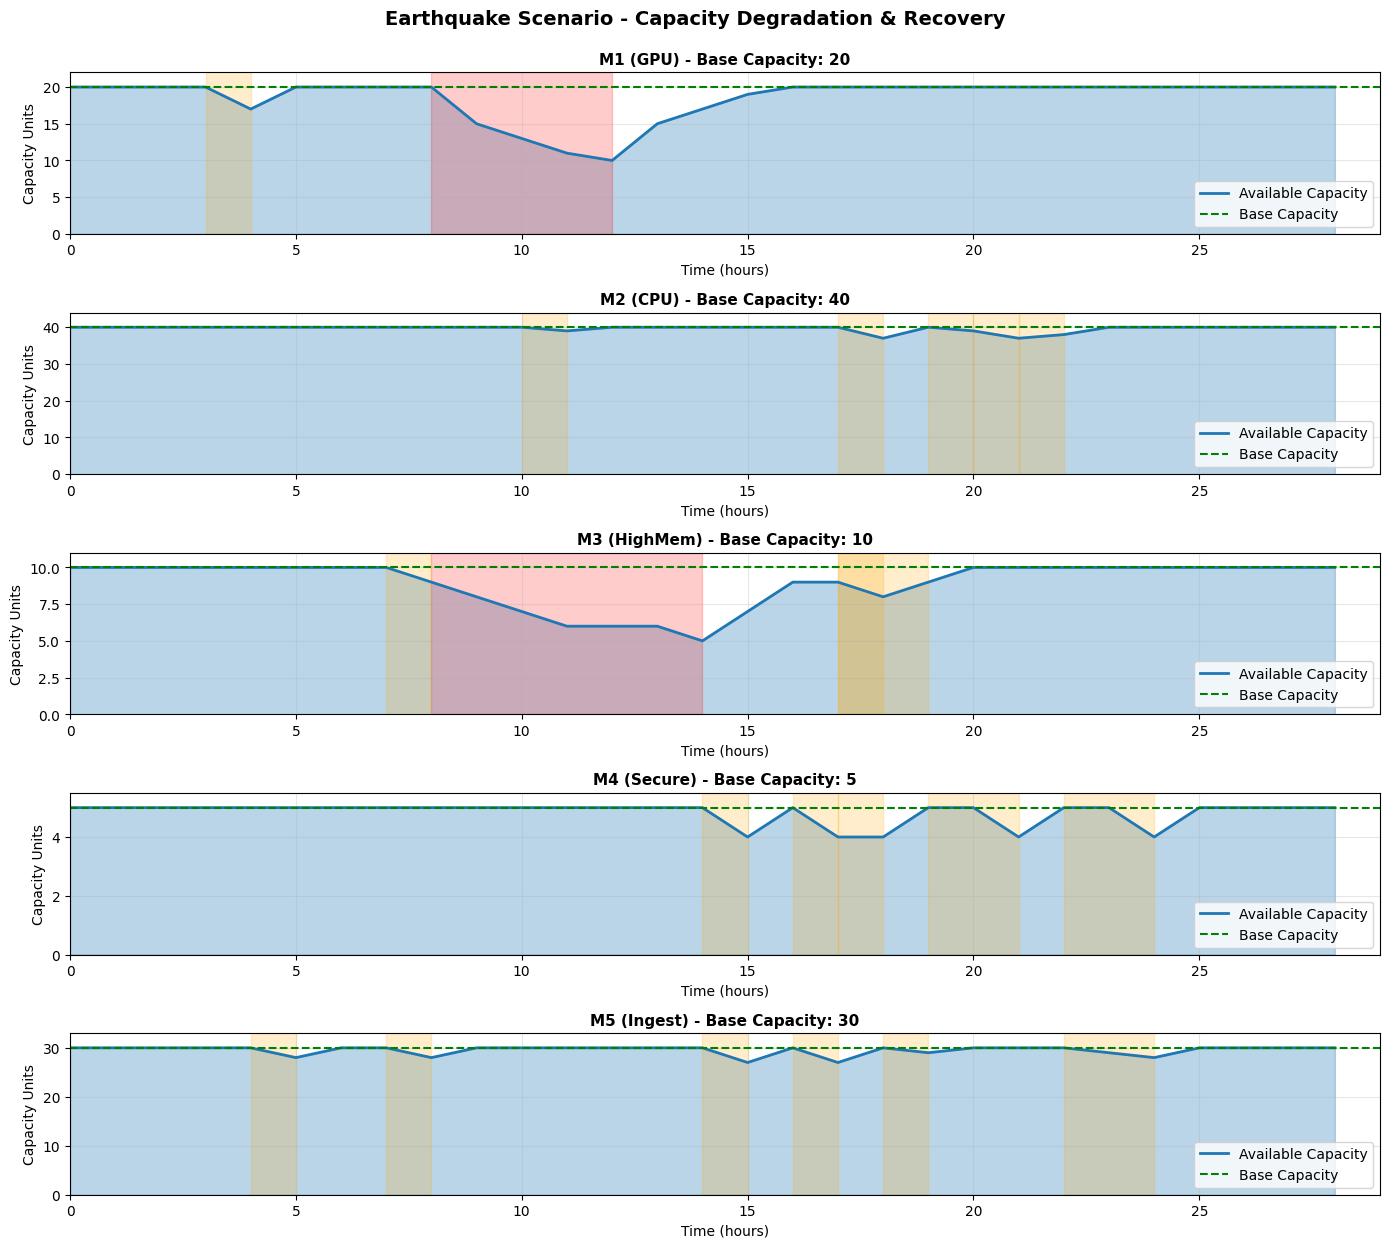

In [ ]:
def plot_capacity_over_time(inst, title="Available Capacity Over Time"):
    """
    Plot how available capacity changes over time due to failures.
    """
    import math
    
    def get_available_capacity(server_id, time):
        """Calculate available capacity considering exponential failure/recovery."""
        server = inst.servers[server_id]
        base_capacity = server.capacity
        
        if not inst.machine_failures:
            return base_capacity
        
        total_reduction = 0
        for failure in inst.machine_failures:
            if failure.machine_id != server_id:
                continue
            
            if time < failure.failure_start:
                continue
            elif time >= failure.failure_end:
                time_since_end = time - failure.failure_end
                recovery_factor = 1.0 - math.exp(-failure.recovery_rate * time_since_end)
                reduction = failure.capacity_reduction * (1.0 - recovery_factor)
                total_reduction += reduction
            else:
                time_since_start = time - failure.failure_start
                failure_factor = 1.0 - math.exp(-failure.failure_rate * time_since_start)
                reduction = failure.capacity_reduction * failure_factor
                total_reduction += reduction
        
        return max(0, base_capacity - int(total_reduction))
    
    # Get local machines only
    local_machines = [s for s_id, s in inst.servers.items() if not s.is_cloud]
    
    if not local_machines:
        print("No local machines to plot")
        return
    
    fig, axes = plt.subplots(len(local_machines), 1, figsize=(14, len(local_machines)*2.5))
    if len(local_machines) == 1:
        axes = [axes]
    
    for idx, server in enumerate(sorted(local_machines, key=lambda s: s.id)):
        time_range = range(inst.time_horizon + 5)  # Include recovery period
        capacities = [get_available_capacity(server.id, t) for t in time_range]
        
        axes[idx].plot(time_range, capacities, linewidth=2, color='#1f77b4', label='Available Capacity')
        axes[idx].axhline(y=server.capacity, color='g', linestyle='--', linewidth=1.5, label='Base Capacity')
        axes[idx].fill_between(time_range, 0, capacities, alpha=0.3, color='#1f77b4')
        
        # Mark failure events
        if inst.machine_failures:
            for failure in inst.machine_failures:
                if failure.machine_id == server.id:
                    axes[idx].axvspan(failure.failure_start, failure.failure_end, 
                                    alpha=0.2, color='red' if not failure.is_random else 'orange')
        
        axes[idx].set_title(f'{server.id} ({server.server_type}) - Base Capacity: {server.capacity}',
                          fontsize=11, fontweight='bold')
        axes[idx].set_xlabel('Time (hours)')
        axes[idx].set_ylabel('Capacity Units')
        axes[idx].legend(loc='lower right')
        axes[idx].grid(alpha=0.3)
        axes[idx].set_xlim(0, inst.time_horizon + 5)
        axes[idx].set_ylim(0, server.capacity * 1.1)
    
    plt.suptitle(title, fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()

# Plot for earthquake scenario with combined failures
plot_capacity_over_time(earthquake_inst_random, 
                       "Earthquake Scenario - Capacity Degradation & Recovery")

### 6.1 Capacity Over Time with Failures

FAILURE TIMELINE VISUALIZATIONS


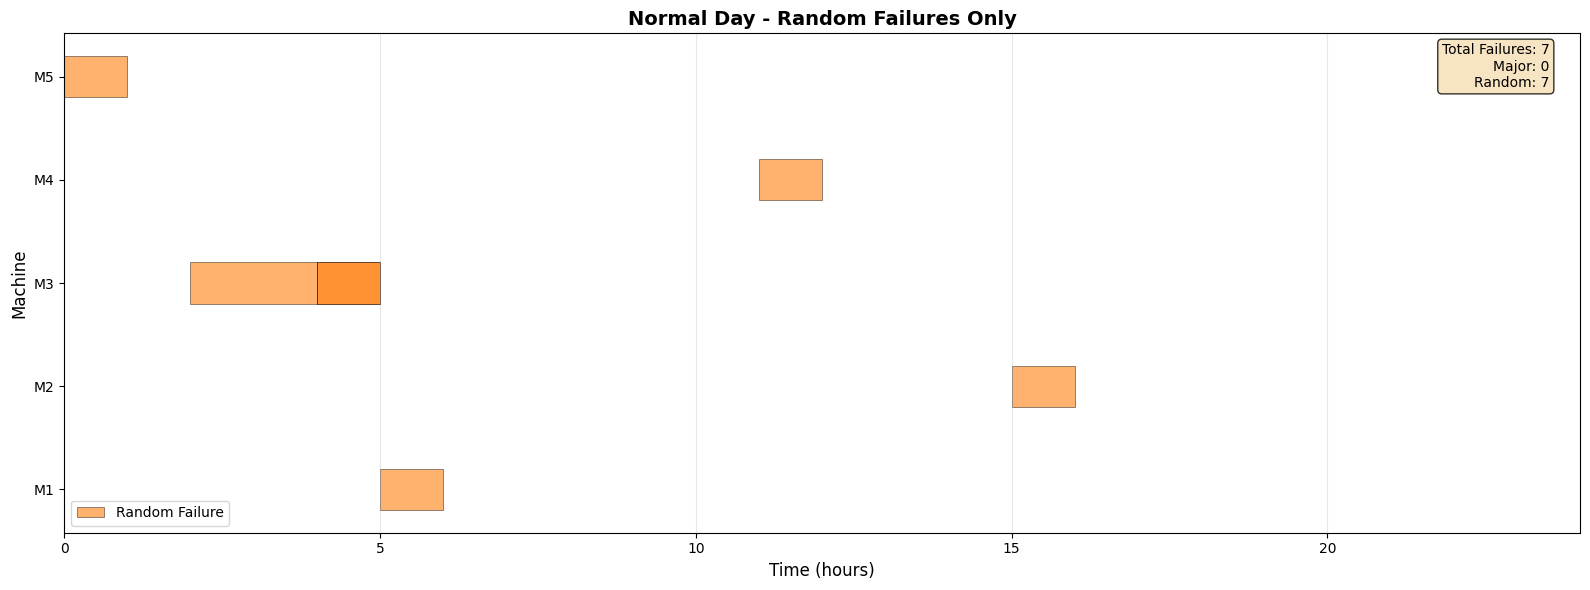

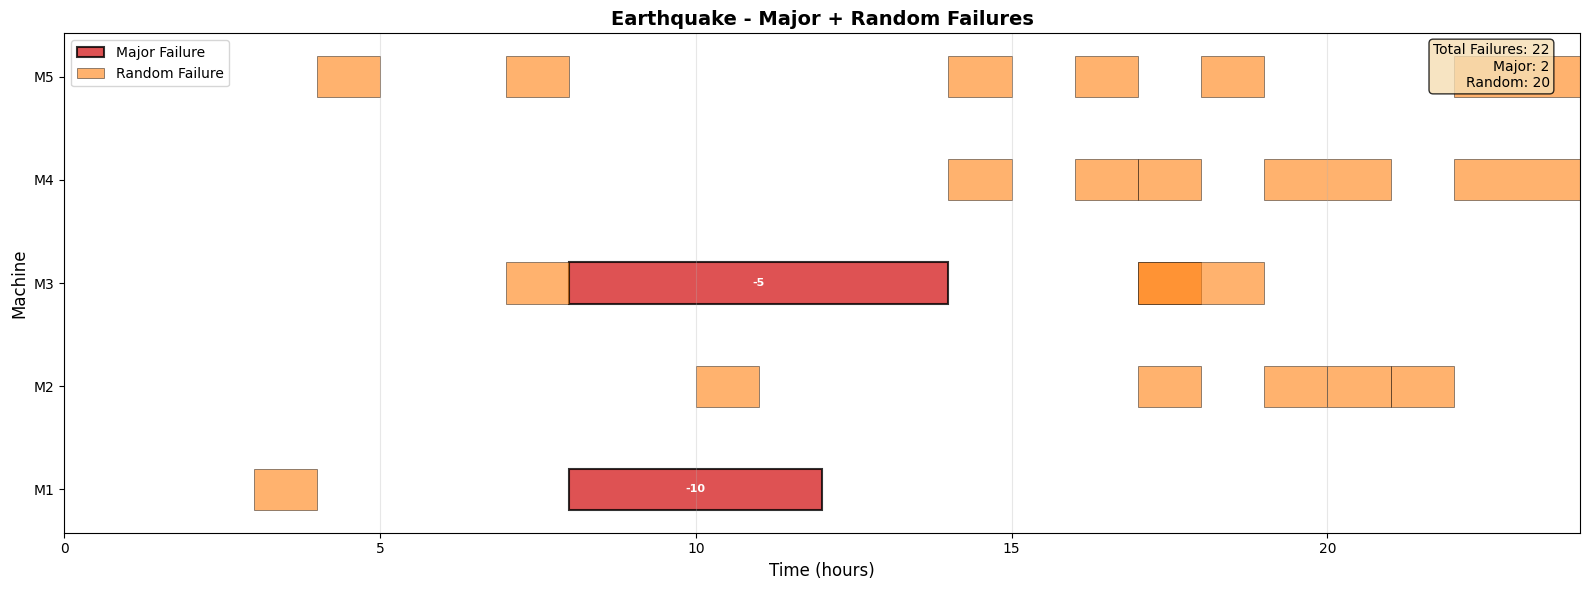

In [ ]:
def visualize_failures(inst, title="Machine Failure Timeline"):
    """
    Visualize machine failures over time.
    """
    if not inst.machine_failures:
        print("No failures to visualize")
        return
    
    # Separate major and random failures
    major_failures = [f for f in inst.machine_failures if not f.is_random]
    random_failures = [f for f in inst.machine_failures if f.is_random]
    
    # Get unique machines
    machines = sorted(set(f.machine_id for f in inst.machine_failures))
    machine_to_y = {m: i for i, m in enumerate(machines)}
    
    fig, ax = plt.subplots(figsize=(16, max(6, len(machines) * 0.8)))
    
    # Plot major failures
    for failure in major_failures:
        y_pos = machine_to_y[failure.machine_id]
        duration = failure.failure_end - failure.failure_start
        ax.barh(y_pos, duration, left=failure.failure_start,
               height=0.4, color='#d62728', alpha=0.8,
               edgecolor='black', linewidth=1.5, label='Major Failure' if failure == major_failures[0] else '')
        
        # Add capacity reduction label
        ax.text(failure.failure_start + duration/2, y_pos, f'-{failure.capacity_reduction}',
               ha='center', va='center', fontsize=8, fontweight='bold', color='white')
    
    # Plot random failures
    for failure in random_failures:
        y_pos = machine_to_y[failure.machine_id]
        duration = failure.failure_end - failure.failure_start
        ax.barh(y_pos, duration, left=failure.failure_start,
               height=0.4, color='#ff7f0e', alpha=0.6,
               edgecolor='black', linewidth=0.5, label='Random Failure' if failure == random_failures[0] else '')
    
    ax.set_yticks(range(len(machines)))
    ax.set_yticklabels(machines)
    ax.set_xlabel('Time (hours)', fontsize=12)
    ax.set_ylabel('Machine', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    ax.set_xlim(0, inst.time_horizon)
    ax.legend(fontsize=10)
    
    # Add statistics
    stats_text = f"Total Failures: {len(inst.machine_failures)}\n"
    stats_text += f"Major: {len(major_failures)}\n"
    stats_text += f"Random: {len(random_failures)}"
    
    ax.text(0.98, 0.98, stats_text, transform=ax.transAxes,
           fontsize=10, verticalalignment='top', horizontalalignment='right',
           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    plt.tight_layout()
    plt.show()

# Visualize failures for both scenarios
print("=" * 60)
print("FAILURE TIMELINE VISUALIZATIONS")
print("=" * 60)

# Normal scenario with random failures
visualize_failures(normal_inst_random, "Normal Day - Random Failures Only")

# Earthquake scenario with combined failures
visualize_failures(earthquake_inst_random, "Earthquake - Major + Random Failures")

## 7. Failure Timeline Visualization

In [ ]:
print("=" * 80)
print("FINAL SUMMARY: ONLINE vs CLAIRVOYANT")
print("=" * 80)

summary_df = pd.DataFrame([
    {
        'Metric': 'Normal - Online Cost',
        'Value': f'¥{online_normal_score:.2f}'
    },
    {
        'Metric': 'Normal - Clairvoyant Cost',
        'Value': f'¥{clairvoyant_normal_score:.2f}'
    },
    {
        'Metric': 'Normal - Competitive Ratio',
        'Value': f'{online_normal_score/clairvoyant_normal_score:.3f}x'
    },
    {
        'Metric': 'Earthquake - Online Cost',
        'Value': f'¥{online_eq_score:.2f}'
    },
    {
        'Metric': 'Earthquake - Clairvoyant Cost',
        'Value': f'¥{clairvoyant_eq_score:.2f}'
    },
    {
        'Metric': 'Earthquake - Competitive Ratio',
        'Value': f'{online_eq_score/clairvoyant_eq_score:.3f}x'
    },
    {
        'Metric': 'Weighted - Online Cost',
        'Value': f'¥{online_weighted:.2f}'
    },
    {
        'Metric': 'Weighted - Clairvoyant Cost',
        'Value': f'¥{clairvoyant_weighted:.2f}'
    },
    {
        'Metric': 'Weighted - Competitive Ratio',
        'Value': f'{online_weighted/clairvoyant_weighted:.3f}x'
    }
])

print(summary_df.to_string(index=False))

print("\n" + "=" * 80)
print("KEY INSIGHTS")
print("=" * 80)
normal_gap = (online_normal_score - clairvoyant_normal_score) / clairvoyant_normal_score * 100
eq_gap = (online_eq_score - clairvoyant_eq_score) / clairvoyant_eq_score * 100
weighted_gap = (online_weighted - clairvoyant_weighted) / clairvoyant_weighted * 100

print(f"\n✓ Online vs Clairvoyant competitive ratio: {online_weighted/clairvoyant_weighted:.3f}x")
print(f"✓ Normal day gap: {normal_gap:.1f}%")
print(f"✓ Earthquake scenario gap: {eq_gap:.1f}%")
print(f"\n✓ Price of being online (no future knowledge): ¥{online_weighted - clairvoyant_weighted:.2f}")
print(f"  - Normal scenario: ¥{online_normal_score - clairvoyant_normal_score:.2f}")
print(f"  - Earthquake scenario: ¥{online_eq_score - clairvoyant_eq_score:.2f}")

print("\n" + "=" * 80)
print("RANDOM FAILURE FEATURE")
print("=" * 80)
print(f"✓ Random failures simulate realistic operational issues")
print(f"✓ Small capacity reductions (1-3 units, <15% of capacity)")
print(f"✓ Short duration (1-2 hours) with fast recovery")
print(f"✓ Exponential inter-arrival times (configurable MTBF)")
print(f"✓ Can be enabled/disabled for testing")
print(f"✓ Cost impact: {weighted_impact:.2f}% (realistic noise level)")

FINAL SUMMARY
                   Metric     Value
       Normal - FIFO Cost  ¥4360.00
    Normal - Optimal Cost ¥13051.00
             Normal - Gap   -66.59%
   Earthquake - FIFO Cost ¥12765.00
Earthquake - Optimal Cost ¥26453.00
         Earthquake - Gap   -51.74%
     Weighted - FIFO Cost  ¥6041.00
  Weighted - Optimal Cost ¥15731.40
           Weighted - Gap   -61.60%

KEY INSIGHTS

✓ The FIFO scheduler is -61.6% away from optimal
✓ Normal day performance gap: -66.6%
✓ Earthquake scenario gap: -51.7%

✓ Potential savings with optimal scheduling: ¥-9690.40
  - Normal scenario: ¥-8691.00
  - Earthquake scenario: ¥-13688.00

RANDOM FAILURE FEATURE
✓ Random failures simulate realistic operational issues
✓ Small capacity reductions (1-3 units, <15% of capacity)
✓ Short duration (1-2 hours) with fast recovery
✓ Exponential inter-arrival times (configurable MTBF)
✓ Can be enabled/disabled for testing
✓ Minimal cost impact: 0.00% (realistic noise level)
